# Class-wise q-Gaussian regularization: q = 0.5

A q-Gaussian companion to [`Synthetic_TPReg.ipynb`](Synthetic_TPReg.ipynb).
Keep the same three Gaussian **input** classes, nonlinear encoder, fixed simplex
means, matched initialization and batch order, and snapshots at epochs 1, 5, 10,
and 100. The **embedding** targets are now spherical **q-Gaussians with q=0.5**,
also called biweight distributions.

Compare **FYLoss** and **QGaussianRegFYLoss**. The class-wise
regularizer uses the projected CF of the q=0.5 law, with a positive Gaussian
integration window. Both this experiment and the TP experiment now have
actual within-class covariance $I_D/D$. The density normalizer, support
radius, joint Fenchel–Young loss, projected CF, exact sampler, Q–Q targets,
and radial CDF differ between the two distributions. Train on all training
examples; there is no calibration stage.

Run from `EDA/` with PyTorch, NumPy, and Matplotlib installed. The head and
regularizer in this notebook implement q=0.5 specifically. Training can take
several minutes on a GPU; reduce the settings below for a smoke run.

## Setup and experiment settings

In [1]:
import json
import math
from copy import deepcopy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset, TensorDataset

from qgda import (
    SimplexQGaussianHead, qgaussian_joint_fy_loss, ClasswiseQGaussianReg,
)

TRAIN_SIZE, TEST_SIZE = 20_000, 4_000
BATCH_SIZE, EVAL_BATCH_SIZE = 256, 1024
PLOT_SIZE = 1000
checkpoint_epochs = (1, 5, 10, 100)
comparison_seed = 7
q_weight = 1.0
num_slices = 256
num_integration_points = 65
diagnostic_integration_points = 129
qreg_warmup_epochs = 5
qreg_ramp_epochs = 5
Q_SHAPE_RULE = '[pi^(D/2) / (8 * Gamma(D/2 + 3)) * (1 + 6/D)^(D/2 + 2)]^(1/2) * I_D'
loss_names = ('FYLoss', 'QGaussianRegFYLoss')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
output_dir = Path('results/synthetic_qgaussian_q05')
plot_dir = Path('plots')
print('device =', device)

device = cuda


## The same synthetic input data

In [2]:
C, separation = 3, 1.7
NUM_CLASSES, D = C, 2
LABEL_OFFSET = 1
pi = torch.full((C,), 1 / C)
base_mus = torch.tensor([[-2.0, -0.5], [2.2, 0.2], [-0.5, 2.3]])
mus = base_mus * separation
input_covariance = torch.tensor([[1.0, 0.35], [0.35, 1.1]])
chol = torch.linalg.cholesky(input_covariance)


def sample_dataset(n_total, seed):
    generator = torch.Generator().manual_seed(seed)
    labels = torch.multinomial(pi, n_total, replacement=True, generator=generator)
    noise = torch.randn(n_total, 2, generator=generator)
    x = noise @ chol.T + mus[labels]
    order = torch.randperm(n_total, generator=generator)
    return x[order], (labels + LABEL_OFFSET)[order]


train_X, train_y = sample_dataset(TRAIN_SIZE, seed=7)
test_X, test_y = sample_dataset(TEST_SIZE, seed=137)
train_ds = TensorDataset(train_X, train_y)
test_ds = TensorDataset(test_X, test_y)
test_ld = DataLoader(test_ds, batch_size=EVAL_BATCH_SIZE, shuffle=False,
                     generator=torch.Generator().manual_seed(137))
print('Training:', len(train_ds), 'Test:', len(test_ds))

Training: 20000 Test: 4000


## Fixed simplex q-Gaussian head and nonlinear encoder

In [3]:
class DeepQGaussian(nn.Module):
    def __init__(self, C, D):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(2, 32), nn.ReLU(), nn.Linear(32, D))
        self.head = SimplexQGaussianHead(C, D, q=0.5)  # Fixed shape giving moment covariance I_D / D.

    def forward(self, x):
        return self.head(self.encoder(x))


reference_head = SimplexQGaussianHead(C, D, q=0.5)
print('q=0.5 shape rule:', Q_SHAPE_RULE)
print('q=0.5 shape matrix:', reference_head.covariance)
print('q=0.5 moment covariance:', reference_head.moment_covariance)
print('Support radius:', reference_head.support_radius.item())

# For D=2, the new rule gives v=sqrt(4*pi/3), moment covariance I_2/2, R=2.
if D == 2:
    torch.testing.assert_close(reference_head.covariance, torch.eye(D) * math.sqrt(4 * math.pi / 3))
    torch.testing.assert_close(reference_head.moment_covariance, torch.eye(D) / 2)
    torch.testing.assert_close(reference_head.support_radius, torch.tensor(2.0))
print('Minimum mean distance:', torch.pdist(reference_head.mu).min().item())
print('Supports disjoint:', bool(torch.pdist(reference_head.mu).min() > 2 * reference_head.support_radius))

q=0.5 shape rule: [pi^(D/2) / (8 * Gamma(D/2 + 3)) * (1 + 6/D)^(D/2 + 2)]^(1/2) * I_D
q=0.5 shape matrix: tensor([[2.0467, 0.0000],
        [0.0000, 2.0467]])
q=0.5 moment covariance: tensor([[0.5000, 0.0000],
        [0.0000, 0.5000]])
Support radius: 2.0
Minimum mean distance: 6.0
Supports disjoint: True


## q = 0.5 density and projected characteristic function

We use the Tsallis/Fenchel–Young convention $\alpha=2-q=1.5$, following
[Martins et al., *Sparse Continuous Distributions and Fenchel-Young Losses*,
Section 6 and the parameter convention in Section 4](https://jmlr.org/papers/v23/21-0879.html).
Here $q$ is the q-exponential parameter. Write $b=1-q=1/2$, $k=1/b=2$,
and $Q_c(z)=\lVert z-\mu_c\rVert^2/v_D$. The normalized class density is

$$
p(z\mid c)=[b(a-Q_c(z)/2)]_+^k
=A\left(1-\frac{\lVert z-\mu_c\rVert^2}{R^2}\right)_+^2,
\qquad A=(ba)^2,\qquad R^2=2v_Da.
$$

Normalization by radial integration gives

$$
a=\left[\frac{\Gamma(D/2+k+1)}
{\Gamma(k+1)(2\pi v_D)^{D/2}b^k}\right]^{1/(D/2+k)}.
$$

This is a q-Gaussian because the profile exponent is $1/(1-q)=2$; TP has
exponent 1 and corresponds to $q=0$. `tau()` returns $-a$, preserving the
shape convention used by EDA's TP head. The shared fixed matrix
$\Sigma=v_DI_D$ parameterizes the quadratic score. Its **moment covariance** is

$$
\operatorname{Cov}(Z\mid c)=\frac{R^2}{D+6}I_D
=\frac{2av_D}{D+6}I_D.
$$

To obtain actual covariance $I_D/D$, require $av_D=(D+6)/(2D)$.
Substituting this into the normalization equation gives the new default shape:

$$
\Sigma=v_DI_D,\qquad
v_D=\left[
\frac{\pi^{D/2}}{8\Gamma(D/2+3)}
\left(1+\frac{6}{D}\right)^{D/2+2}
\right]^{1/2}.
$$

Consequently,

$$
R^2=1+\frac{6}{D},\qquad
\operatorname{Cov}(Z\mid c)=\frac{1}{D}I_D,\qquad
\mathbb{E}\!\left[\lVert Z-\mu_c\rVert^2\right]=1.
$$

For this notebook's $D=2$ experiment, the exact values are

$$
v_2=\sqrt{\frac{4\pi}{3}},\qquad
a=\sqrt{\frac{3}{\pi}},\qquad
R=2,\qquad
\operatorname{Cov}(Z\mid c)=\frac{1}{2}I_2.
$$

The head computes the shape coefficient and normalization in log space.
An explicit `variance` selects another fixed shape scale. Only encoder
parameters and class priors are optimized.

For $U=(Z-\mu_c)/R$, any unit projection $u\in[-1,1]$ has marginal density

$$
g_D(u)=\frac{\Gamma(D/2+3)}{\sqrt{\pi}\,\Gamma((D+5)/2)}
(1-u^2)^{(D+3)/2},\qquad
(u+1)/2\sim\operatorname{Beta}((D+5)/2,(D+5)/2).
$$

Residuals are standardized using the **fixed moment** standard deviation:

$$
r=(z-\mu_c)\frac{\sqrt{D+6}}{R}=\sqrt{D}\,(z-\mu_c).
$$

The last equality holds for the new default shape. The general radius-based
standardization also supports explicit shape overrides. The standardized
q=0.5 target CF is unchanged by the new shape rule. Applying the
[Bessel integral representation (DLMF 10.9.4)](https://dlmf.nist.gov/10.9.E4)
to the projection marginal gives

$$
\phi_{D,0.5}(t)=\Gamma(D/2+3)
\left(\frac{2}{\sqrt{D+6}|t|}\right)^{D/2+2}
J_{D/2+2}(\sqrt{D+6}|t|),\qquad \phi_{D,0.5}(0)=1.
$$

`ClasswiseQGaussianReg` evaluates the equivalent cosine integral with a
64-point Gauss–Jacobi rule in float64 at initialization, then caches its CF
grid. The shared machinery in `qgda.py` is parameterized by the radial power;
TP keeps power 1 and this experiment uses power 2. `QGaussianRegFYLoss`
already takes the updated support radius from the head.

Adapt [LeJEPA's projected CF mechanism](https://arxiv.org/abs/2511.08544) by
matching each class separately to this q-Gaussian target:

$$
\widehat{\phi}_{c,m}(t)=\frac{1}{n_c}\sum_{i:y_i=c}e^{it a_m^\top r_i},
$$

$$
T_c=\frac{n_c}{M}\sum_m\operatorname{trapz}_{t\in[-5,5]}
\left[|\widehat{\phi}_{c,m}(t)-\phi_{D,0.5}(t)|^2e^{-t^2/2}\right],
\qquad\mathcal{R}_q=\sum_c\frac{n_c}{N}T_c.
$$

The Gaussian factor is only a positive integration window: the target CF can
be negative and cannot serve as that weight. Directions are resampled each
minibatch with an independent seeded RNG. Fixed class centers and scales are
never estimated from the batch. Absent and singleton classes contribute zero
without renormalizing other weights.

Use 256 directions and 65 frequency points for training, and 129 frequency
points for diagnostics. Finite projections, frequency truncation, quadrature,
and finite weight encourage rather than guarantee a q-Gaussian fit. A uniform
frequency grid can alias large translations, and the sample-count multiplier
makes regularization strength depend on batch size.

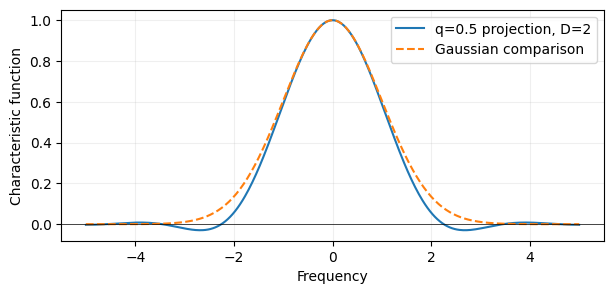

In [4]:
# Inspect the actual target: it differs from the Gaussian CF.
cf_check = ClasswiseQGaussianReg(D)
frequencies = torch.linspace(-5, 5, 401, dtype=torch.float64)
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(frequencies, cf_check.projected_cf(frequencies), label=f'q=0.5 projection, D={D}')
ax.plot(frequencies, torch.exp(-frequencies.square() / 2), '--', label='Gaussian comparison')
ax.axhline(0, color='black', linewidth=0.5)
ax.set(xlabel='Frequency', ylabel='Characteristic function')
ax.legend(); ax.grid(alpha=0.2)
plt.show()

## q-Gaussian joint Fenchel–Young loss and compact support

The head returns **joint densities** $p(c,z)=\pi_c p(z\mid c)$. A true
q-Gaussian NLL is infinite outside the target class support; clipping it
would remove the gradients there. We use a joint FY loss with the correct
Tsallis exponent $\alpha=1.5$, rather than TP's $\alpha=2$ formula.

For $\Omega_\alpha(p)=(\int p^\alpha-1)/(\alpha(\alpha-1))$, the generating
joint score is $f(c,z)=\pi_c^{\alpha-1}(a-Q_c(z)/2)$. Direct integration gives

$$
\int p(z\mid c)^\alpha dz=\frac{2a\alpha}{D+6},\qquad
\Omega_\alpha^*(f)=\frac1{\alpha(\alpha-1)}
+\frac{2a}{D+6}\sum_c\pi_c^\alpha.
$$

The attached joint loss is therefore

$$
\ell_{\mathrm{FY}}(z,y)=\frac1{\alpha(\alpha-1)}
+\frac{2a}{D+6}\sum_c\pi_c^\alpha
+\pi_y^{\alpha-1}\left(\tfrac12Q_y(z)-a\right).
$$

This retains embedding gradients outside the support. In particular, both the
prior power and the global term differ from the TP loss. The comparison is:

- **FYLoss**: mean q=0.5 joint FY loss from `qgda.py`.
- **QGaussianRegFYLoss**: q-Gaussian FY plus $\lambda_q\mathcal{R}_q$.

Q-Gaussian regularization starts after 5 FY-only epochs, ramping to full weight
over 5 epochs. This is the explicit optimization schedule from the TP notebook.
All runs share initial parameters, batch order, fixed geometry, and total epochs.

A point outside every class support is **uncovered**, receives prediction `-1`,
and counts as incorrect. Report both accuracy and coverage. The Gaussian input
classes overlap, whereas the prescribed q-Gaussian supports have radius $2$
and pairwise mean distance $6>2\times 2$, so they are disjoint. A deterministic
encoder cannot map all of these overlapping class distributions exactly to those
disjoint targets; inspect held-out tails
and support violations as well as the main clusters.

In [5]:
def predict_with_support(scores):
    covered = scores.max(1).values > 0
    prediction = scores.argmax(1).masked_fill(~covered, -1)
    return prediction, covered


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    correct = covered_count = total = 0
    model_device = next(model.parameters()).device
    for X, y in loader:
        X, y = X.to(model_device), y.to(model_device) - LABEL_OFFSET
        prediction, covered = predict_with_support(model(X))
        correct += (prediction == y).sum().item()
        covered_count += covered.sum().item()
        total += len(y)
    return dict(accuracy=correct / total, coverage=covered_count / total)


plot_indices = torch.randperm(len(train_ds), generator=torch.Generator().manual_seed(137))[:PLOT_SIZE]
embedding_ld = DataLoader(Subset(train_ds, plot_indices.tolist()),
                          batch_size=EVAL_BATCH_SIZE, shuffle=False,
                          generator=torch.Generator().manual_seed(137))


@torch.no_grad()
def capture_embeddings(model):
    model.eval()
    embeddings, labels = [], []
    for X, y in embedding_ld:
        embeddings.append(model.encoder(X.to(device)).cpu())
        labels.append(y)
    return dict(embeddings=torch.cat(embeddings), labels=torch.cat(labels),
                centers=model.head.mu.detach().cpu().clone(),
                variance=model.head.variance.detach().cpu().clone(),
                tau=model.head.tau().detach().cpu().clone(),
                radius=model.head.support_radius.item(),
                priors=model.head.priors().detach().cpu().clone())


def qreg_weight_for_epoch(epoch):
    if epoch <= qreg_warmup_epochs:
        return 0.0
    return q_weight * min(1.0, (epoch - qreg_warmup_epochs) / max(1, qreg_ramp_epochs))


def train_comparison_run(loss_name, initial_state):
    torch.manual_seed(comparison_seed)
    model = DeepQGaussian(NUM_CLASSES, D).to(device)
    model.load_state_dict(initial_state)
    optimizer = torch.optim.Adam(model.parameters())
    regularizer = ClasswiseQGaussianReg(D, num_slices=num_slices,
                                   num_points=num_integration_points).to(device)
    run_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                             generator=torch.Generator().manual_seed(comparison_seed))
    snapshots, history = {}, []
    step = 0
    for epoch in range(1, max(checkpoint_epochs) + 1):
        model.train()
        loss_sum = fy_sum = penalty_sum = correct = covered_count = total = 0
        weight = qreg_weight_for_epoch(epoch) if loss_name == 'QGaussianRegFYLoss' else 0.0
        for X, y in run_loader:
            X, y = X.to(device), y.to(device) - LABEL_OFFSET
            z = model.encoder(X)
            fy = qgaussian_joint_fy_loss(model.head, z, y).mean()
            penalty = z.new_zeros(())
            if weight:
                penalty = regularizer(
                    z, y, model.head.mu, radius=model.head.support_radius, step=step,
                )
            loss = fy + weight * penalty
            if not torch.isfinite(loss):
                raise RuntimeError(f'Non-finite {loss_name} at epoch {epoch}, step {step}')
            with torch.no_grad():
                prediction, covered = predict_with_support(model.head(z))
                correct += (prediction == y).sum().item()
                covered_count += covered.sum().item()
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
            n = len(y)
            loss_sum += loss.item() * n
            fy_sum += fy.item() * n
            penalty_sum += penalty.item() * n
            total += n
            step += 1
        test = evaluate(model, test_ld)
        row = dict(epoch=epoch, loss=loss_sum / total, fy=fy_sum / total,
                   penalty=penalty_sum / total, regularization_weight=weight,
                   train_accuracy=correct / total, train_coverage=covered_count / total,
                   test_accuracy=test['accuracy'], test_coverage=test['coverage'])
        history.append(row)
        if epoch in checkpoint_epochs:
            snapshots[epoch] = capture_embeddings(model)
            print(f"[{loss_name} epoch {epoch:03d}] FY={row['fy']:.4f} "
                  f"penalty={row['penalty']:.4f} weight={weight:.2f} "
                  f"test acc={row['test_accuracy']:.4f} coverage={row['test_coverage']:.4f}")
    return model.eval().cpu(), snapshots, history

## Train both objectives

Test data reports performance; it does not select checkpoints or tune the settings.

In [6]:
torch.manual_seed(comparison_seed)
initial_state = deepcopy(DeepQGaussian(NUM_CLASSES, D).state_dict())
comparison_models, embedding_snapshots, training_history = {}, {}, {}
for loss_name in loss_names:
    (comparison_models[loss_name], embedding_snapshots[loss_name],
     training_history[loss_name]) = train_comparison_run(loss_name, initial_state)

[FYLoss epoch 001] FY=2.0975 penalty=0.0000 weight=0.00 test acc=0.4313 coverage=0.4313
[FYLoss epoch 005] FY=1.0701 penalty=0.0000 weight=0.00 test acc=0.9537 coverage=0.9543
[FYLoss epoch 010] FY=1.0308 penalty=0.0000 weight=0.00 test acc=0.9670 coverage=0.9677
[FYLoss epoch 100] FY=0.9370 penalty=0.0000 weight=0.00 test acc=0.9908 coverage=0.9930
[QGaussianRegFYLoss epoch 001] FY=2.0975 penalty=0.0000 weight=0.00 test acc=0.4313 coverage=0.4313
[QGaussianRegFYLoss epoch 005] FY=1.0701 penalty=0.0000 weight=0.00 test acc=0.9537 coverage=0.9543
[QGaussianRegFYLoss epoch 010] FY=1.0949 penalty=1.8856 weight=1.00 test acc=0.9520 coverage=0.9525
[QGaussianRegFYLoss epoch 100] FY=1.0778 penalty=1.3018 weight=1.00 test acc=0.9667 coverage=0.9683


## Compare embeddings across epochs

All panels use the same training examples and coordinate limits. Crosses mark
fixed class centers; dashed circles mark actual q=0.5 support boundaries.
Decision shading uses the **squared** positive-part density and the saved priors.
White regions lie outside all class supports.

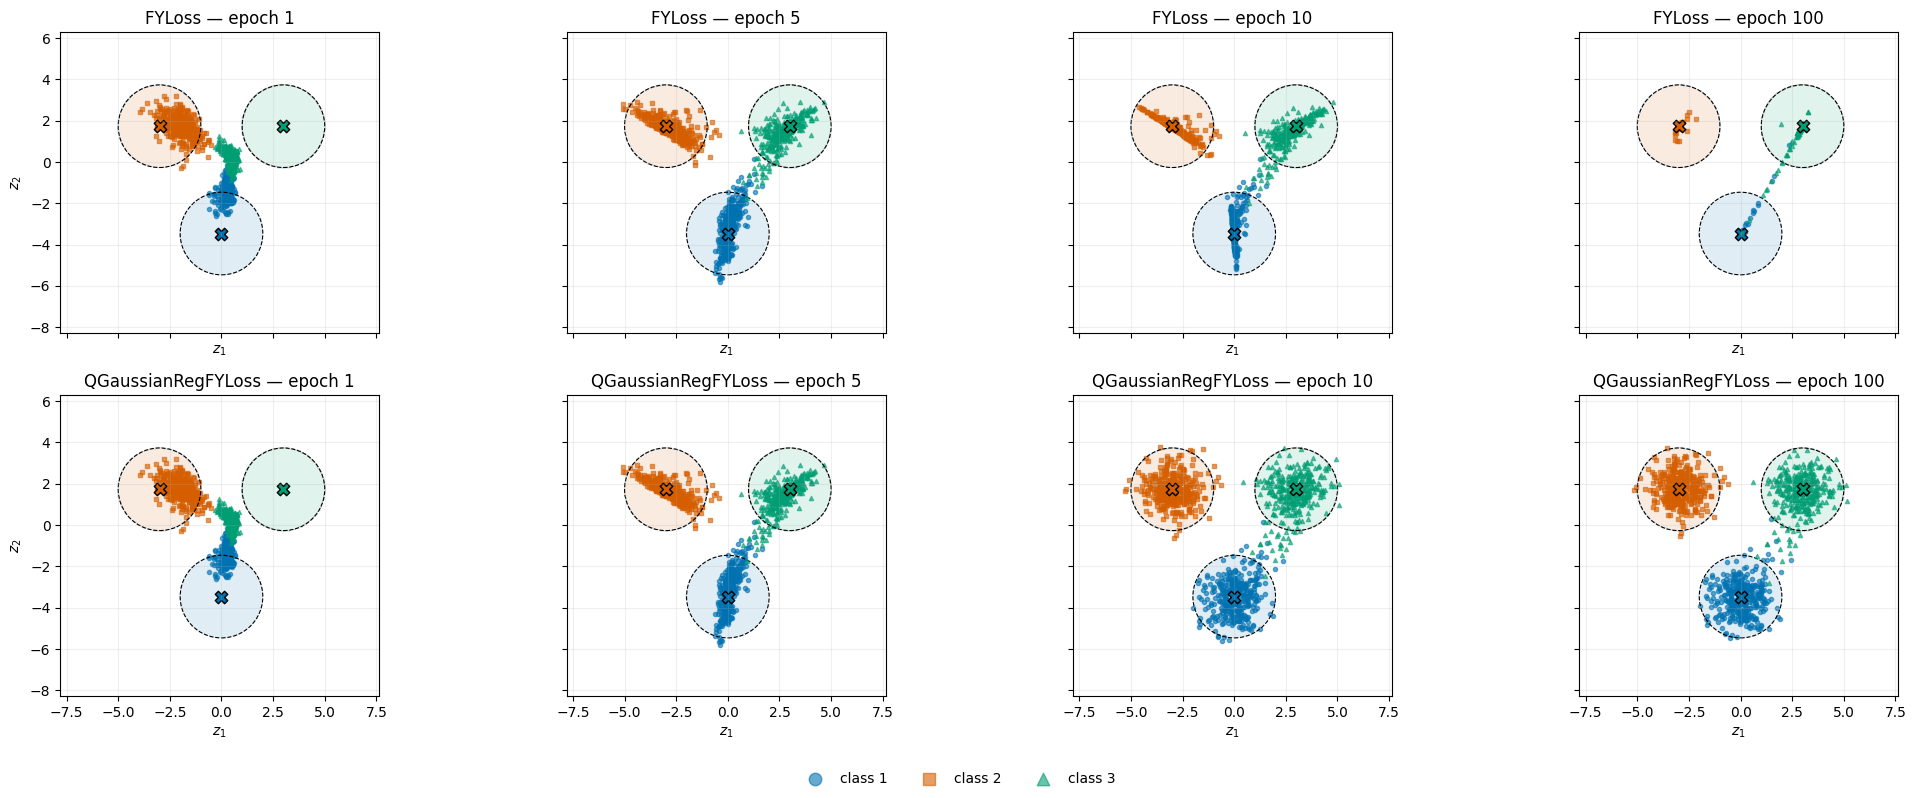

In [7]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Circle

colors = ['#0072B2', '#D55E00', '#009E73']
markers = ['o', 's', '^']
plot_dir.mkdir(parents=True, exist_ok=True)
all_points = torch.cat([
    snapshot['embeddings'] for snapshots in embedding_snapshots.values()
    for snapshot in snapshots.values()
] + [snapshot['centers'] for snapshots in embedding_snapshots.values()
     for snapshot in snapshots.values()])
margin = 1.25 * max(s['radius'] for snaps in embedding_snapshots.values() for s in snaps.values())
low = all_points.min(0).values.numpy() - margin
high = all_points.max(0).values.numpy() + margin
xx, yy = np.meshgrid(np.linspace(low[0], high[0], 240), np.linspace(low[1], high[1], 240))
grid = np.c_[xx.ravel(), yy.ravel()]
fig, axes = plt.subplots(len(loss_names), len(checkpoint_epochs),
                         figsize=(21, 4 * len(loss_names)), sharex=True, sharey=True, squeeze=False)
for row, loss_name in enumerate(loss_names):
    for col, epoch in enumerate(checkpoint_epochs):
        ax = axes[row, col]
        snapshot = embedding_snapshots[loss_name][epoch]
        Z, Y = snapshot['embeddings'].numpy(), snapshot['labels'].numpy()
        centers = snapshot['centers'].numpy()
        squared_distance = ((grid[:, None] - centers[None]) ** 2).sum(-1)
        densities = np.maximum(0.5 * (-snapshot['tau'].numpy()[None] - 0.5 * squared_distance / float(snapshot['variance'])), 0) ** 2
        scores = densities * snapshot['priors'].numpy()[None]
        regions = np.where(scores.max(1) > 0, scores.argmax(1) + 1, 0).reshape(xx.shape)
        ax.contourf(xx, yy, regions, levels=np.arange(NUM_CLASSES + 2) - 0.5,
                    cmap=ListedColormap(['white'] + colors), alpha=0.12)
        for c in range(NUM_CLASSES):
            mask = Y == c + LABEL_OFFSET
            ax.scatter(Z[mask, 0], Z[mask, 1], s=9, alpha=0.6,
                       color=colors[c], marker=markers[c], label=f'class {c + LABEL_OFFSET}')
            ax.scatter(*centers[c], marker='X', s=80, color=colors[c], edgecolor='black')
            ax.add_patch(Circle(centers[c], snapshot['radius'], fill=False,
                                edgecolor='black', linestyle='--', linewidth=0.8))
        ax.set_title(f'{loss_name} — epoch {epoch}')
        ax.set_xlim(low[0], high[0]); ax.set_ylim(low[1], high[1])
        ax.set_aspect('equal', adjustable='box')
        ax.grid(alpha=0.2)
        ax.set_xlabel('$z_1$')
        if col == 0:
            ax.set_ylabel('$z_2$')
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=NUM_CLASSES, frameon=False, markerscale=3)
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(plot_dir / 'synth_q05_fy_qreg_epochs.png', dpi=180, bbox_inches='tight')
plt.show()